In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

from xgboost import XGBClassifier

import joblib

print("Libraries imported successfully.")

Libraries imported successfully.


In [2]:
train_path = "Dataset/UNSW_NB15_training-set.csv"
test_path = "Dataset/UNSW_NB15_testing-set.csv"

print("Training dataset:", train_path)
print("Testing dataset :", test_path)

Training dataset: Dataset/UNSW_NB15_training-set.csv
Testing dataset : Dataset/UNSW_NB15_testing-set.csv


In [3]:
train_df = pd.read_csv(train_path)
test_df = pd.read_csv(test_path)

print("Training shape:", train_df.shape)
print("Testing shape :", test_df.shape)

Training shape: (82332, 45)
Testing shape : (175341, 45)


In [4]:
print("Training Dataset:")
display(train_df.head())

print("\nTesting Dataset:")
display(test_df.head())

Training Dataset:


,id,dur,proto,service,state,spkts,dpkts,sbytes,dbytes,rate,...,ct_dst_sport_ltm,ct_dst_src_ltm,is_ftp_login,ct_ftp_cmd,ct_flw_http_mthd,ct_src_ltm,ct_srv_dst,is_sm_ips_ports,attack_cat,label
0,1,0.000011,udp,-,INT,2,0,496,0,90909.0902,...,1,2,0,0,0,1,2,0,Normal,0
1,2,0.000008,udp,-,INT,2,0,1762,0,125000.0003,...,1,2,0,0,0,1,2,0,Normal,0
2,3,0.000005,udp,-,INT,2,0,1068,0,200000.0051,...,1,3,0,0,0,1,3,0,Normal,0
3,4,0.000006,udp,-,INT,2,0,900,0,166666.6608,...,1,3,0,0,0,2,3,0,Normal,0
4,5,0.000010,udp,-,INT,2,0,2126,0,100000.0025,...,1,3,0,0,0,2,3,0,Normal,0



Testing Dataset:


,id,dur,proto,service,state,spkts,dpkts,sbytes,dbytes,rate,...,ct_dst_sport_ltm,ct_dst_src_ltm,is_ftp_login,ct_ftp_cmd,ct_flw_http_mthd,ct_src_ltm,ct_srv_dst,is_sm_ips_ports,attack_cat,label
0,1,0.121478,tcp,-,FIN,6,4,258,172,74.087490,...,1,1,0,0,0,1,1,0,Normal,0
1,2,0.649902,tcp,-,FIN,14,38,734,42014,78.473372,...,1,2,0,0,0,1,6,0,Normal,0
2,3,1.623129,tcp,-,FIN,8,16,364,13186,14.170161,...,1,3,0,0,0,2,6,0,Normal,0
3,4,1.681642,tcp,ftp,FIN,12,12,628,770,13.677108,...,1,3,1,1,0,2,1,0,Normal,0
4,5,0.449454,tcp,-,FIN,10,6,534,268,33.373826,...,1,40,0,0,0,2,39,0,Normal,0


In [5]:
print("Training Dataset Information")
print("=" * 50)

train_df.info()

Training Dataset Information
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 82332 entries, 0 to 82331
Data columns (total 45 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 82332 non-null  int64  
 1   dur                82332 non-null  float64
 2   proto              82332 non-null  object 
 3   service            82332 non-null  object 
 4   state              82332 non-null  object 
 5   spkts              82332 non-null  int64  
 6   dpkts              82332 non-null  int64  
 7   sbytes             82332 non-null  int64  
 8   dbytes             82332 non-null  int64  
 9   rate               82332 non-null  float64
 10  sttl               82332 non-null  int64  
 11  dttl               82332 non-null  int64  
 12  sload              82332 non-null  float64
 13  dload              82332 non-null  float64
 14  sloss              82332 non-null  int64  
 15  dloss              82332 non-null  int64 

In [6]:
print("Missing values in training dataset:")
print(train_df.isnull().sum())

print("\nTotal missing values:",
      train_df.isnull().sum().sum())

print("\nMissing values in testing dataset:")
print(test_df.isnull().sum())

print("\nTotal missing values:",
      test_df.isnull().sum().sum())

Missing values in training dataset:
id                   0
dur                  0
proto                0
service              0
state                0
spkts                0
dpkts                0
sbytes               0
dbytes               0
rate                 0
sttl                 0
dttl                 0
sload                0
dload                0
sloss                0
dloss                0
sinpkt               0
dinpkt               0
sjit                 0
djit                 0
swin                 0
stcpb                0
dtcpb                0
dwin                 0
tcprtt               0
synack               0
ackdat               0
smean                0
dmean                0
trans_depth          0
response_body_len    0
ct_srv_src           0
ct_state_ttl         0
ct_dst_ltm           0
ct_src_dport_ltm     0
ct_dst_sport_ltm     0
ct_dst_src_ltm       0
is_ftp_login         0
ct_ftp_cmd           0
ct_flw_http_mthd     0
ct_src_ltm           0
ct_srv_dst           

In [7]:
print("Training Label Distribution")
print(train_df["label"].value_counts())

print("\nTesting Label Distribution")
print(test_df["label"].value_counts())

Training Label Distribution
label
1    45332
0    37000
Name: count, dtype: int64

Testing Label Distribution
label
1    119341
0     56000
Name: count, dtype: int64


In [8]:
print("Attack Category Distribution")
print(train_df["attack_cat"].value_counts())

Attack Category Distribution
attack_cat
Normal            37000
Generic           18871
Exploits          11132
Fuzzers            6062
DoS                4089
Reconnaissance     3496
Analysis            677
Backdoor            583
Shellcode           378
Worms                44
Name: count, dtype: int64


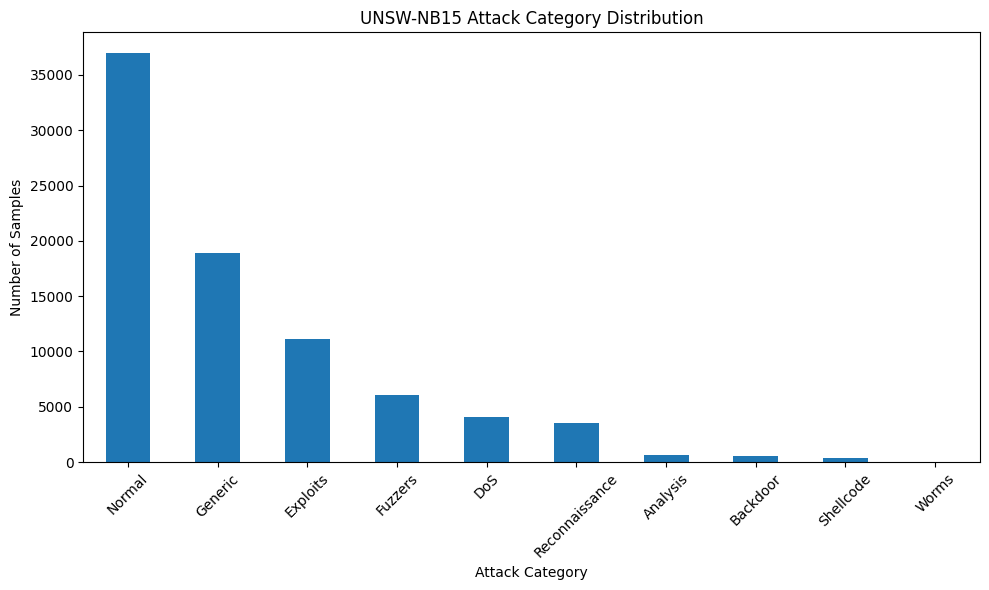

In [9]:
plt.figure(figsize=(10, 6))

train_df["attack_cat"].value_counts().plot(
    kind="bar"
)

plt.title("UNSW-NB15 Attack Category Distribution")
plt.xlabel("Attack Category")
plt.ylabel("Number of Samples")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [10]:
X_train = train_df.drop(
    columns=["label", "attack_cat"],
    errors="ignore"
)

y_train = train_df["label"]

X_test = test_df.drop(
    columns=["label", "attack_cat"],
    errors="ignore"
)

y_test = test_df["label"]

print("X_train shape:", X_train.shape)
print("X_test shape :", X_test.shape)

print("y_train shape:", y_train.shape)
print("y_test shape :", y_test.shape)

X_train shape: (82332, 43)
X_test shape : (175341, 43)
y_train shape: (82332,)
y_test shape : (175341,)


In [11]:
if "id" in X_train.columns:
    X_train = X_train.drop(columns=["id"])

if "id" in X_test.columns:
    X_test = X_test.drop(columns=["id"])

print("X_train shape after removing ID:", X_train.shape)
print("X_test shape after removing ID :", X_test.shape)

X_train shape after removing ID: (82332, 42)
X_test shape after removing ID : (175341, 42)


In [12]:
categorical_features = [
    col for col in ["proto", "service", "state"]
    if col in X_train.columns
]

numerical_features = [
    col for col in X_train.columns
    if col not in categorical_features
]

print("Categorical Features:")
print(categorical_features)

print("\nNumber of Numerical Features:",
      len(numerical_features))

print("\nTotal Features:",
      len(X_train.columns))

Categorical Features:
['proto', 'service', 'state']

Number of Numerical Features: 39

Total Features: 42


In [13]:
preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=False
            ),
            categorical_features
        ),
        (
            "numerical",
            StandardScaler(),
            numerical_features
        )
    ]
)

print("Preprocessing pipeline created successfully.")

Preprocessing pipeline created successfully.


In [14]:
X_train_processed = preprocessor.fit_transform(
    X_train
)

print(
    "Processed training shape:",
    X_train_processed.shape
)

Processed training shape: (82332, 190)


In [15]:
X_test_processed = preprocessor.transform(
    X_test
)

print(
    "Processed testing shape:",
    X_test_processed.shape
)

Processed testing shape: (175341, 190)


In [16]:
feature_names = (
    preprocessor
    .get_feature_names_out()
)

print("Total processed features:",
      len(feature_names))

print("\nFirst 30 processed features:")
print(feature_names[:30])

Total processed features: 190

First 30 processed features:
['categorical__proto_3pc' 'categorical__proto_a/n'
 'categorical__proto_aes-sp3-d' 'categorical__proto_any'
 'categorical__proto_argus' 'categorical__proto_aris'
 'categorical__proto_arp' 'categorical__proto_ax.25'
 'categorical__proto_bbn-rcc' 'categorical__proto_bna'
 'categorical__proto_br-sat-mon' 'categorical__proto_cbt'
 'categorical__proto_cftp' 'categorical__proto_chaos'
 'categorical__proto_compaq-peer' 'categorical__proto_cphb'
 'categorical__proto_cpnx' 'categorical__proto_crtp'
 'categorical__proto_crudp' 'categorical__proto_dcn'
 'categorical__proto_ddp' 'categorical__proto_ddx'
 'categorical__proto_dgp' 'categorical__proto_egp'
 'categorical__proto_eigrp' 'categorical__proto_emcon'
 'categorical__proto_encap' 'categorical__proto_etherip'
 'categorical__proto_fc' 'categorical__proto_fire']


In [17]:
rf_model = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    n_jobs=-1,
    class_weight="balanced"
)

print("Random Forest model initialized.")

Random Forest model initialized.


In [18]:
print("Training Random Forest...")

rf_model.fit(
    X_train_processed,
    y_train
)

print("Random Forest training completed.")

Training Random Forest...
Random Forest training completed.


In [19]:
rf_pred = rf_model.predict(
    X_test_processed
)

rf_probability = rf_model.predict_proba(
    X_test_processed
)[:, 1]

print("Random Forest predictions generated.")

print("\nFirst 10 predictions:")
print(rf_pred[:10])

print("\nFirst 10 attack probabilities:")
print(rf_probability[:10])

Random Forest predictions generated.

First 10 predictions:
[1 1 1 1 0 0 0 0 1 1]

First 10 attack probabilities:
[0.775 0.875 0.95  0.775 0.375 0.365 0.18  0.445 0.505 0.515]


In [20]:
rf_accuracy = accuracy_score(
    y_test,
    rf_pred
)

rf_precision = precision_score(
    y_test,
    rf_pred,
    zero_division=0
)

rf_recall = recall_score(
    y_test,
    rf_pred,
    zero_division=0
)

rf_f1 = f1_score(
    y_test,
    rf_pred,
    zero_division=0
)

print("=" * 60)
print("RANDOM FOREST PERFORMANCE")
print("=" * 60)

print(f"Accuracy  : {rf_accuracy:.4f}")
print(f"Precision : {rf_precision:.4f}")
print(f"Recall    : {rf_recall:.4f}")
print(f"F1-Score  : {rf_f1:.4f}")

RANDOM FOREST PERFORMANCE
Accuracy  : 0.9040
Precision : 0.9870
Recall    : 0.8704
F1-Score  : 0.9250


In [21]:
print(
    classification_report(
        y_test,
        rf_pred,
        target_names=["Normal", "Attack"],
        zero_division=0
    )
)

              precision    recall  f1-score   support

      Normal       0.78      0.98      0.87     56000
      Attack       0.99      0.87      0.93    119341

    accuracy                           0.90    175341
   macro avg       0.88      0.92      0.90    175341
weighted avg       0.92      0.90      0.91    175341



Random Forest Confusion Matrix:
[[ 54627   1373]
 [ 15463 103878]]


<Figure size 700x600 with 0 Axes>

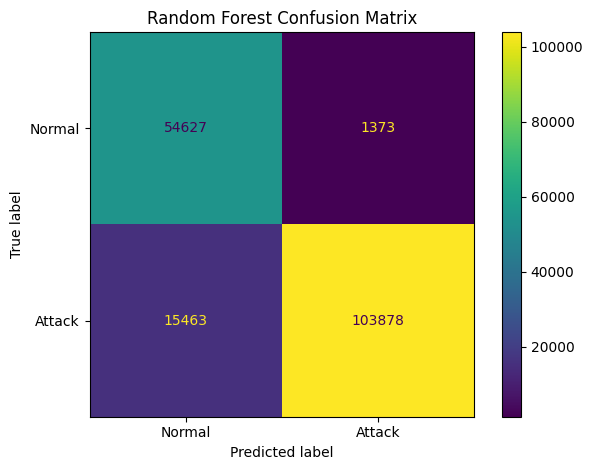

In [22]:
rf_cm = confusion_matrix(
    y_test,
    rf_pred
)

print("Random Forest Confusion Matrix:")
print(rf_cm)

plt.figure(figsize=(7, 6))

disp = ConfusionMatrixDisplay(
    confusion_matrix=rf_cm,
    display_labels=["Normal", "Attack"]
)

disp.plot(values_format="d")

plt.title("Random Forest Confusion Matrix")
plt.tight_layout()
plt.show()

In [23]:
rf_importance = rf_model.feature_importances_

rf_importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": rf_importance
})

rf_importance_df = rf_importance_df.sort_values(
    by="Importance",
    ascending=False
)

print("Top 20 Random Forest Features:")
display(
    rf_importance_df.head(20)
)

Top 20 Random Forest Features:


,Feature,Importance
183,numerical__ct_dst_src_ltm,0.077844
154,numerical__sbytes,0.062281
157,numerical__sttl,0.046150
174,numerical__smean,0.045449
179,numerical__ct_state_ttl,0.043538
182,numerical__ct_dst_sport_ltm,0.042424
148,categorical__state_INT,0.041263
159,numerical__sload,0.038972
188,numerical__ct_srv_dst,0.037851
156,numerical__rate,0.032996


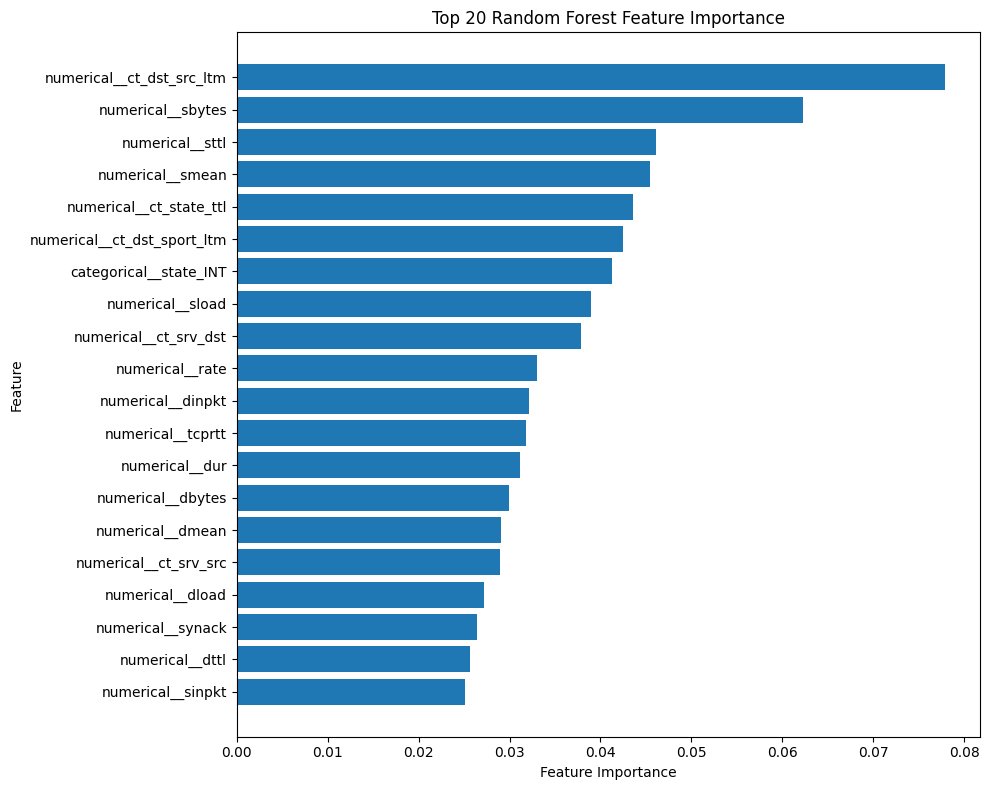

In [24]:
top_rf = rf_importance_df.head(20).sort_values(
    by="Importance"
)

plt.figure(figsize=(10, 8))

plt.barh(
    top_rf["Feature"],
    top_rf["Importance"]
)

plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.title("Top 20 Random Forest Feature Importance")

plt.tight_layout()
plt.show()

In [25]:
xgb_model = XGBClassifier(
    n_estimators=200,
    max_depth=6,
    learning_rate=0.1,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="binary:logistic",
    eval_metric="logloss",
    random_state=42,
    n_jobs=-1
)

print("XGBoost model initialized.")

XGBoost model initialized.


In [26]:
print("Training XGBoost...")

xgb_model.fit(
    X_train_processed,
    y_train
)

print("XGBoost training completed.")

Training XGBoost...
XGBoost training completed.


In [27]:
xgb_pred = xgb_model.predict(
    X_test_processed
)

xgb_probability = xgb_model.predict_proba(
    X_test_processed
)[:, 1]

print("XGBoost predictions generated.")

print("\nFirst 10 predictions:")
print(xgb_pred[:10])

print("\nFirst 10 attack probabilities:")
print(xgb_probability[:10])

XGBoost predictions generated.

First 10 predictions:
[1 1 1 1 0 0 0 0 0 0]

First 10 attack probabilities:
[0.9848956  0.9996253  0.99926394 0.8851338  0.08490427 0.0772111
 0.06029167 0.11828044 0.09500411 0.16913508]


In [28]:
xgb_accuracy = accuracy_score(
    y_test,
    xgb_pred
)

xgb_precision = precision_score(
    y_test,
    xgb_pred,
    zero_division=0
)

xgb_recall = recall_score(
    y_test,
    xgb_pred,
    zero_division=0
)

xgb_f1 = f1_score(
    y_test,
    xgb_pred,
    zero_division=0
)

print("=" * 60)
print("XGBOOST PERFORMANCE")
print("=" * 60)

print(f"Accuracy  : {xgb_accuracy:.4f}")
print(f"Precision : {xgb_precision:.4f}")
print(f"Recall    : {xgb_recall:.4f}")
print(f"F1-Score  : {xgb_f1:.4f}")

XGBOOST PERFORMANCE
Accuracy  : 0.9003
Precision : 0.9882
Recall    : 0.8638
F1-Score  : 0.9218


In [29]:
print(
    classification_report(
        y_test,
        xgb_pred,
        target_names=["Normal", "Attack"],
        zero_division=0
    )
)

              precision    recall  f1-score   support

      Normal       0.77      0.98      0.86     56000
      Attack       0.99      0.86      0.92    119341

    accuracy                           0.90    175341
   macro avg       0.88      0.92      0.89    175341
weighted avg       0.92      0.90      0.90    175341



XGBoost Confusion Matrix:
[[ 54774   1226]
 [ 16257 103084]]


<Figure size 700x600 with 0 Axes>

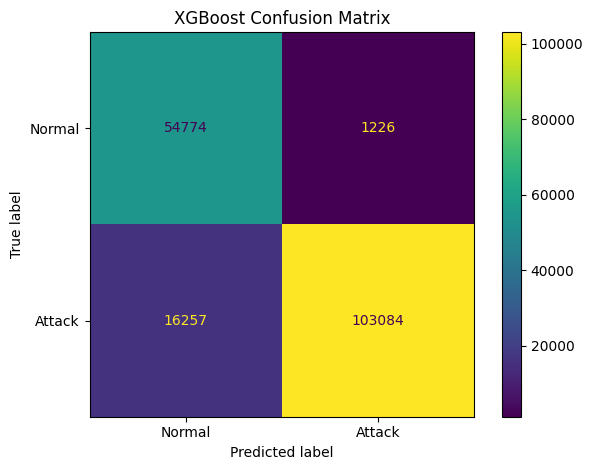

In [30]:
xgb_cm = confusion_matrix(
    y_test,
    xgb_pred
)

print("XGBoost Confusion Matrix:")
print(xgb_cm)

plt.figure(figsize=(7, 6))

disp = ConfusionMatrixDisplay(
    confusion_matrix=xgb_cm,
    display_labels=["Normal", "Attack"]
)

disp.plot(values_format="d")

plt.title("XGBoost Confusion Matrix")
plt.tight_layout()
plt.show()

In [31]:
xgb_importance = xgb_model.feature_importances_

xgb_importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": xgb_importance
})

xgb_importance_df = xgb_importance_df.sort_values(
    by="Importance",
    ascending=False
)

print("Top 20 XGBoost Features:")
display(
    xgb_importance_df.head(20)
)

Top 20 XGBoost Features:


,Feature,Importance
157,numerical__sttl,0.252181
149,categorical__state_REQ,0.139052
182,numerical__ct_dst_sport_ltm,0.090136
117,categorical__proto_udp,0.050753
179,numerical__ct_state_ttl,0.044279
133,categorical__service_dns,0.043411
111,categorical__proto_tcp,0.042909
171,numerical__tcprtt,0.033871
183,numerical__ct_dst_src_ltm,0.033300
172,numerical__synack,0.023094


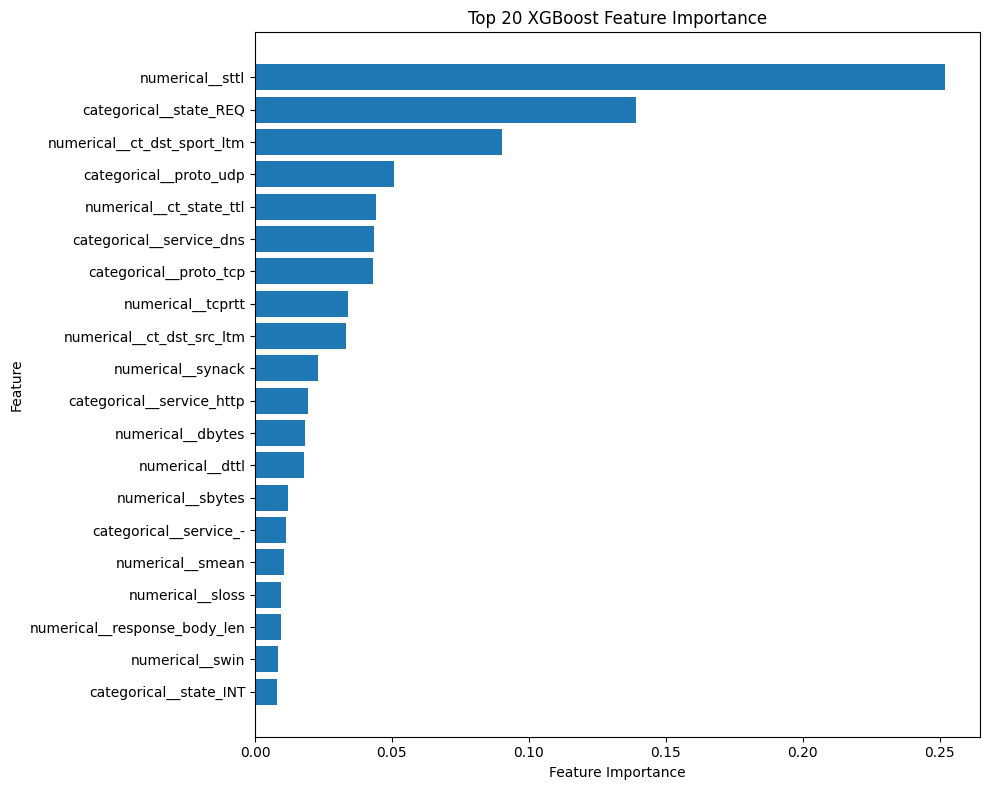

In [32]:
top_xgb = xgb_importance_df.head(20).sort_values(
    by="Importance"
)

plt.figure(figsize=(10, 8))

plt.barh(
    top_xgb["Feature"],
    top_xgb["Importance"]
)

plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.title("Top 20 XGBoost Feature Importance")

plt.tight_layout()
plt.show()

In [33]:
comparison_df = pd.DataFrame({
    "Model": [
        "Random Forest",
        "XGBoost"
    ],
    "Accuracy": [
        rf_accuracy,
        xgb_accuracy
    ],
    "Precision": [
        rf_precision,
        xgb_precision
    ],
    "Recall": [
        rf_recall,
        xgb_recall
    ],
    "F1-Score": [
        rf_f1,
        xgb_f1
    ]
})

display(
    comparison_df.round(4)
)

,Model,Accuracy,Precision,Recall,F1-Score
0,Random Forest,0.9040,0.9870,0.8704,0.9250
1,XGBoost,0.9003,0.9882,0.8638,0.9218


In [34]:
rf_top = rf_importance_df.head(15).copy()
xgb_top = xgb_importance_df.head(15).copy()

print("Top Random Forest Features")
display(rf_top)

print("\nTop XGBoost Features")
display(xgb_top)

Top Random Forest Features


,Feature,Importance
183,numerical__ct_dst_src_ltm,0.077844
154,numerical__sbytes,0.062281
157,numerical__sttl,0.046150
174,numerical__smean,0.045449
179,numerical__ct_state_ttl,0.043538
182,numerical__ct_dst_sport_ltm,0.042424
148,categorical__state_INT,0.041263
159,numerical__sload,0.038972
188,numerical__ct_srv_dst,0.037851
156,numerical__rate,0.032996



Top XGBoost Features


,Feature,Importance
157,numerical__sttl,0.252181
149,categorical__state_REQ,0.139052
182,numerical__ct_dst_sport_ltm,0.090136
117,categorical__proto_udp,0.050753
179,numerical__ct_state_ttl,0.044279
133,categorical__service_dns,0.043411
111,categorical__proto_tcp,0.042909
171,numerical__tcprtt,0.033871
183,numerical__ct_dst_src_ltm,0.033300
172,numerical__synack,0.023094


In [35]:
os.makedirs("models", exist_ok=True)

joblib.dump(
    rf_model,
    "models/unsw_nb15_random_forest.pkl"
)

joblib.dump(
    xgb_model,
    "models/unsw_nb15_xgboost.pkl"
)

joblib.dump(
    preprocessor,
    "models/unsw_nb15_preprocessor.pkl"
)

print("Models and preprocessing pipeline saved successfully.")

Models and preprocessing pipeline saved successfully.


In [36]:
print("Saved model files:")

for file in os.listdir("models"):
    print(file)

Saved model files:
unsw_nb15_preprocessor.pkl
unsw_nb15_random_forest.pkl
unsw_nb15_xgboost.pkl
